# 03 — Composition over time, within lineages

---

**This is the core analysis.** It follows Figures 2 and 3 of the paper.

### Why fit inside lineages

An average across the whole dataset can move for two different reasons:

1. the genomes inside each lineage are genuinely changing, or
2. nothing changes, but a lineage that already had a high value grows while one with a low value shrinks.

The second produces a confident-looking trend with no evolution behind it. Fitting **separately inside each lineage** removes it, which is what the paper does.

### Choosing the lineage level

Full GISAID labels are too fine. Most span only about 6 years with a few hundred genomes, and a regression slope's uncertainty grows as both the time span and the sample size shrink. Truncating the label to **three levels** gives roughly 8 well-populated lineages spanning 2015–2026 — close to the 12 the paper used.

---

In [1]:
import sys, os, subprocess
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = os.path.abspath("..")          # repo root; the R scripts expect to run from here
pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
PAL = {"A": "#2C7FB8", "B": "#C62824"}    # same colours as the R figures

def run_r(script="R/figures.R"):
    """Run the R figure script from the repo root and report what it wrote."""
    r = subprocess.run(["Rscript", script], capture_output=True, text=True, cwd=ROOT)
    print(r.stdout.strip() or r.stderr.strip()[-400:])

def show(fig):
    """Display a figure from results/figures/ inline."""
    display(Image(os.path.join(ROOT, "results", "figures", fig)))
from rsv import lineage

## 3.1  The lineages we analyse

Inclusion requires **at least 5 distinct years and at least 200 genomes**.

In [2]:
g = pd.read_csv("../data/processed/rsv_gene_features.tsv", sep="\t")
dates = pd.read_csv("../data/processed/rsv_features.tsv", sep="\t",
                    usecols=["Accession ID", "date"])
genome = g[(g.gene == "GENOME") & g.year.between(2015, 2026)].merge(dates, on="Accession ID")
gdf, keep = lineage.prepare(genome)
print(f"{len(keep)} lineages, {len(gdf):,} genomes\n")
keep.round(2)

8 lineages, 31,826 genomes



,Subtype,lineage_grp,n,years,first,last
1,A,A.D.1,5090,11,2016.26,2026.50
3,A,A.D.3,4828,10,2017.55,2026.50
5,A,A.D.5,3063,10,2017.00,2026.47
0,A,A.D,1020,11,2015.00,2025.52
2,A,A.D.2,619,12,2015.09,2026.48
4,A,A.D.4,345,9,2015.00,2024.82
7,B,B.D.E,12484,9,2018.03,2026.50
6,B,B.D.4,4377,12,2015.00,2026.42


Note that all eight lineages start between 2015 and 2017 and run to 2025–2026. Because they cover essentially the same calendar window, differences between them are not confounded with *when* they happened to circulate.

RSV-B contributes only two lineages. They are large, so the estimates are sound, but any A-versus-B statement rests on two groups rather than a broad survey.

## 3.2  Trend of each feature within each lineage

Each feature is regressed against the **decimal collection date**, inside each lineage separately. The slope is the change per year.

In [3]:
FEATS = ["gc_content", "gc3", "gc12",
         "per1k_CG", "per1k_GC", "per1k_GG", "per1k_CC", "per1k_TA",
         "oe_CG", "oe_GC", "oe_GG", "oe_CC", "oe_TA"]
slopes = lineage.lineage_slopes(gdf, FEATS)
slopes[slopes.feature == "gc_content"][
    ["Subtype", "lineage_grp", "n", "slope", "ci_lo", "ci_hi", "r2", "significant"]
].round(6)

,Subtype,lineage_grp,n,slope,ci_lo,ci_hi,r2,significant
0,A,A.D,1020,-0.000019,-0.000038,-0.000001,0.004142,True
13,A,A.D.1,5090,0.000046,0.000040,0.000053,0.035380,True
26,A,A.D.2,619,0.000118,0.000101,0.000134,0.243839,True
39,A,A.D.3,4828,-0.000035,-0.000045,-0.000025,0.009368,True
52,A,A.D.4,345,-0.000012,-0.000029,0.000005,0.005387,False
65,A,A.D.5,3063,-0.000115,-0.000127,-0.000103,0.103773,True
78,B,B.D.4,4377,0.000063,0.000057,0.000070,0.082053,True
91,B,B.D.E,12484,0.000069,0.000063,0.000075,0.038323,True


### Figure — GC content over time, one panel per lineage

The equivalent of the paper's Figure 2a. Points are individual genomes; the line is the fitted trend with its confidence band.

In [4]:
run_r()

figures written to results/figures/
fig5 written


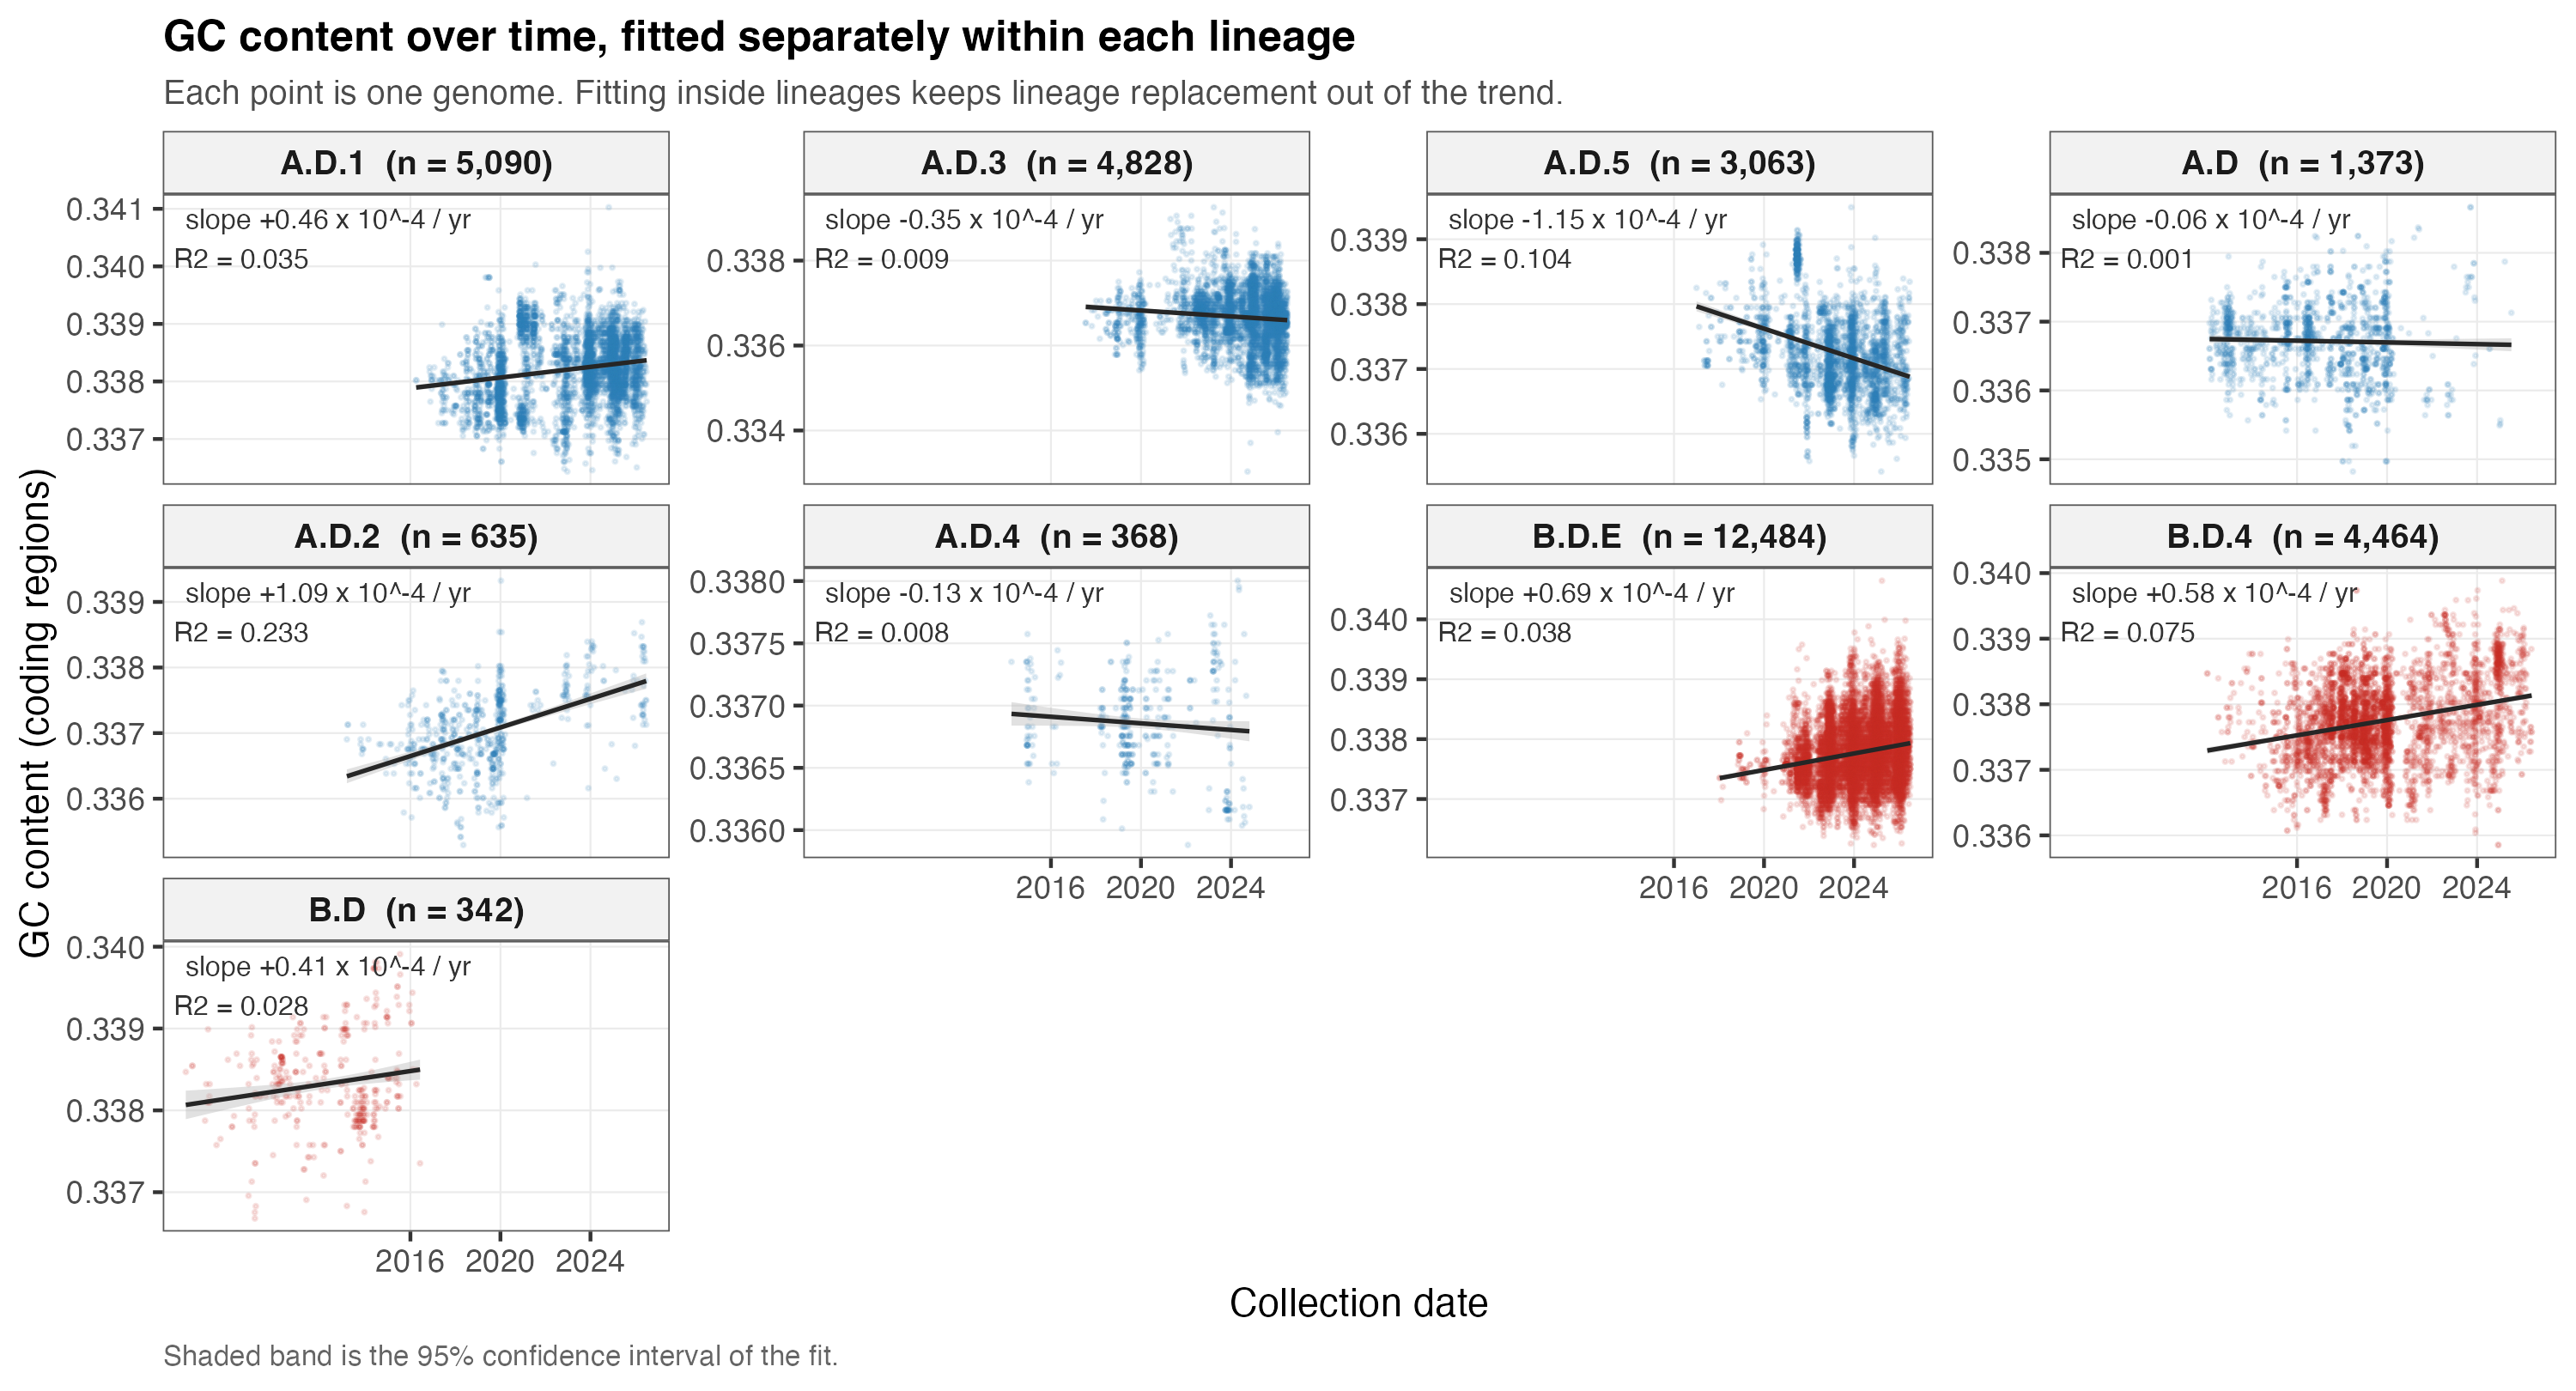

In [5]:
show("fig1_lineage_trends.png")

## 3.3  Where along the codon is GC changing?

This is the sharpest test available. If composition is being pushed by something acting on the RNA, the effect should be strongest at **third codon positions**, where changes are mostly synonymous. If it reflects protein-level constraint, the first and second positions should move comparably.

In [6]:
piv = (slopes[slopes.feature.isin(["gc_content", "gc3", "gc12"])]
       .pivot_table(index=["Subtype", "lineage_grp"], columns="feature", values="slope"))
piv["gc3 / gc12"] = (piv.gc3 / piv.gc12).round(2)
piv.round(6)

feature                  gc12       gc3  gc_content  gc3 / gc12
Subtype lineage_grp                                            
A       A.D         -0.000054  0.000049   -0.000019       -0.91
        A.D.1       -0.000083  0.000305    0.000046       -3.66
        A.D.2        0.000060  0.000230    0.000118        3.80
        A.D.3       -0.000024 -0.000056   -0.000035        2.32
        A.D.4       -0.000208  0.000380   -0.000012       -1.83
        A.D.5       -0.000180  0.000015   -0.000115       -0.08
B       B.D.4       -0.000187  0.000565    0.000063       -3.02
        B.D.E       -0.000134  0.000475    0.000069       -3.54

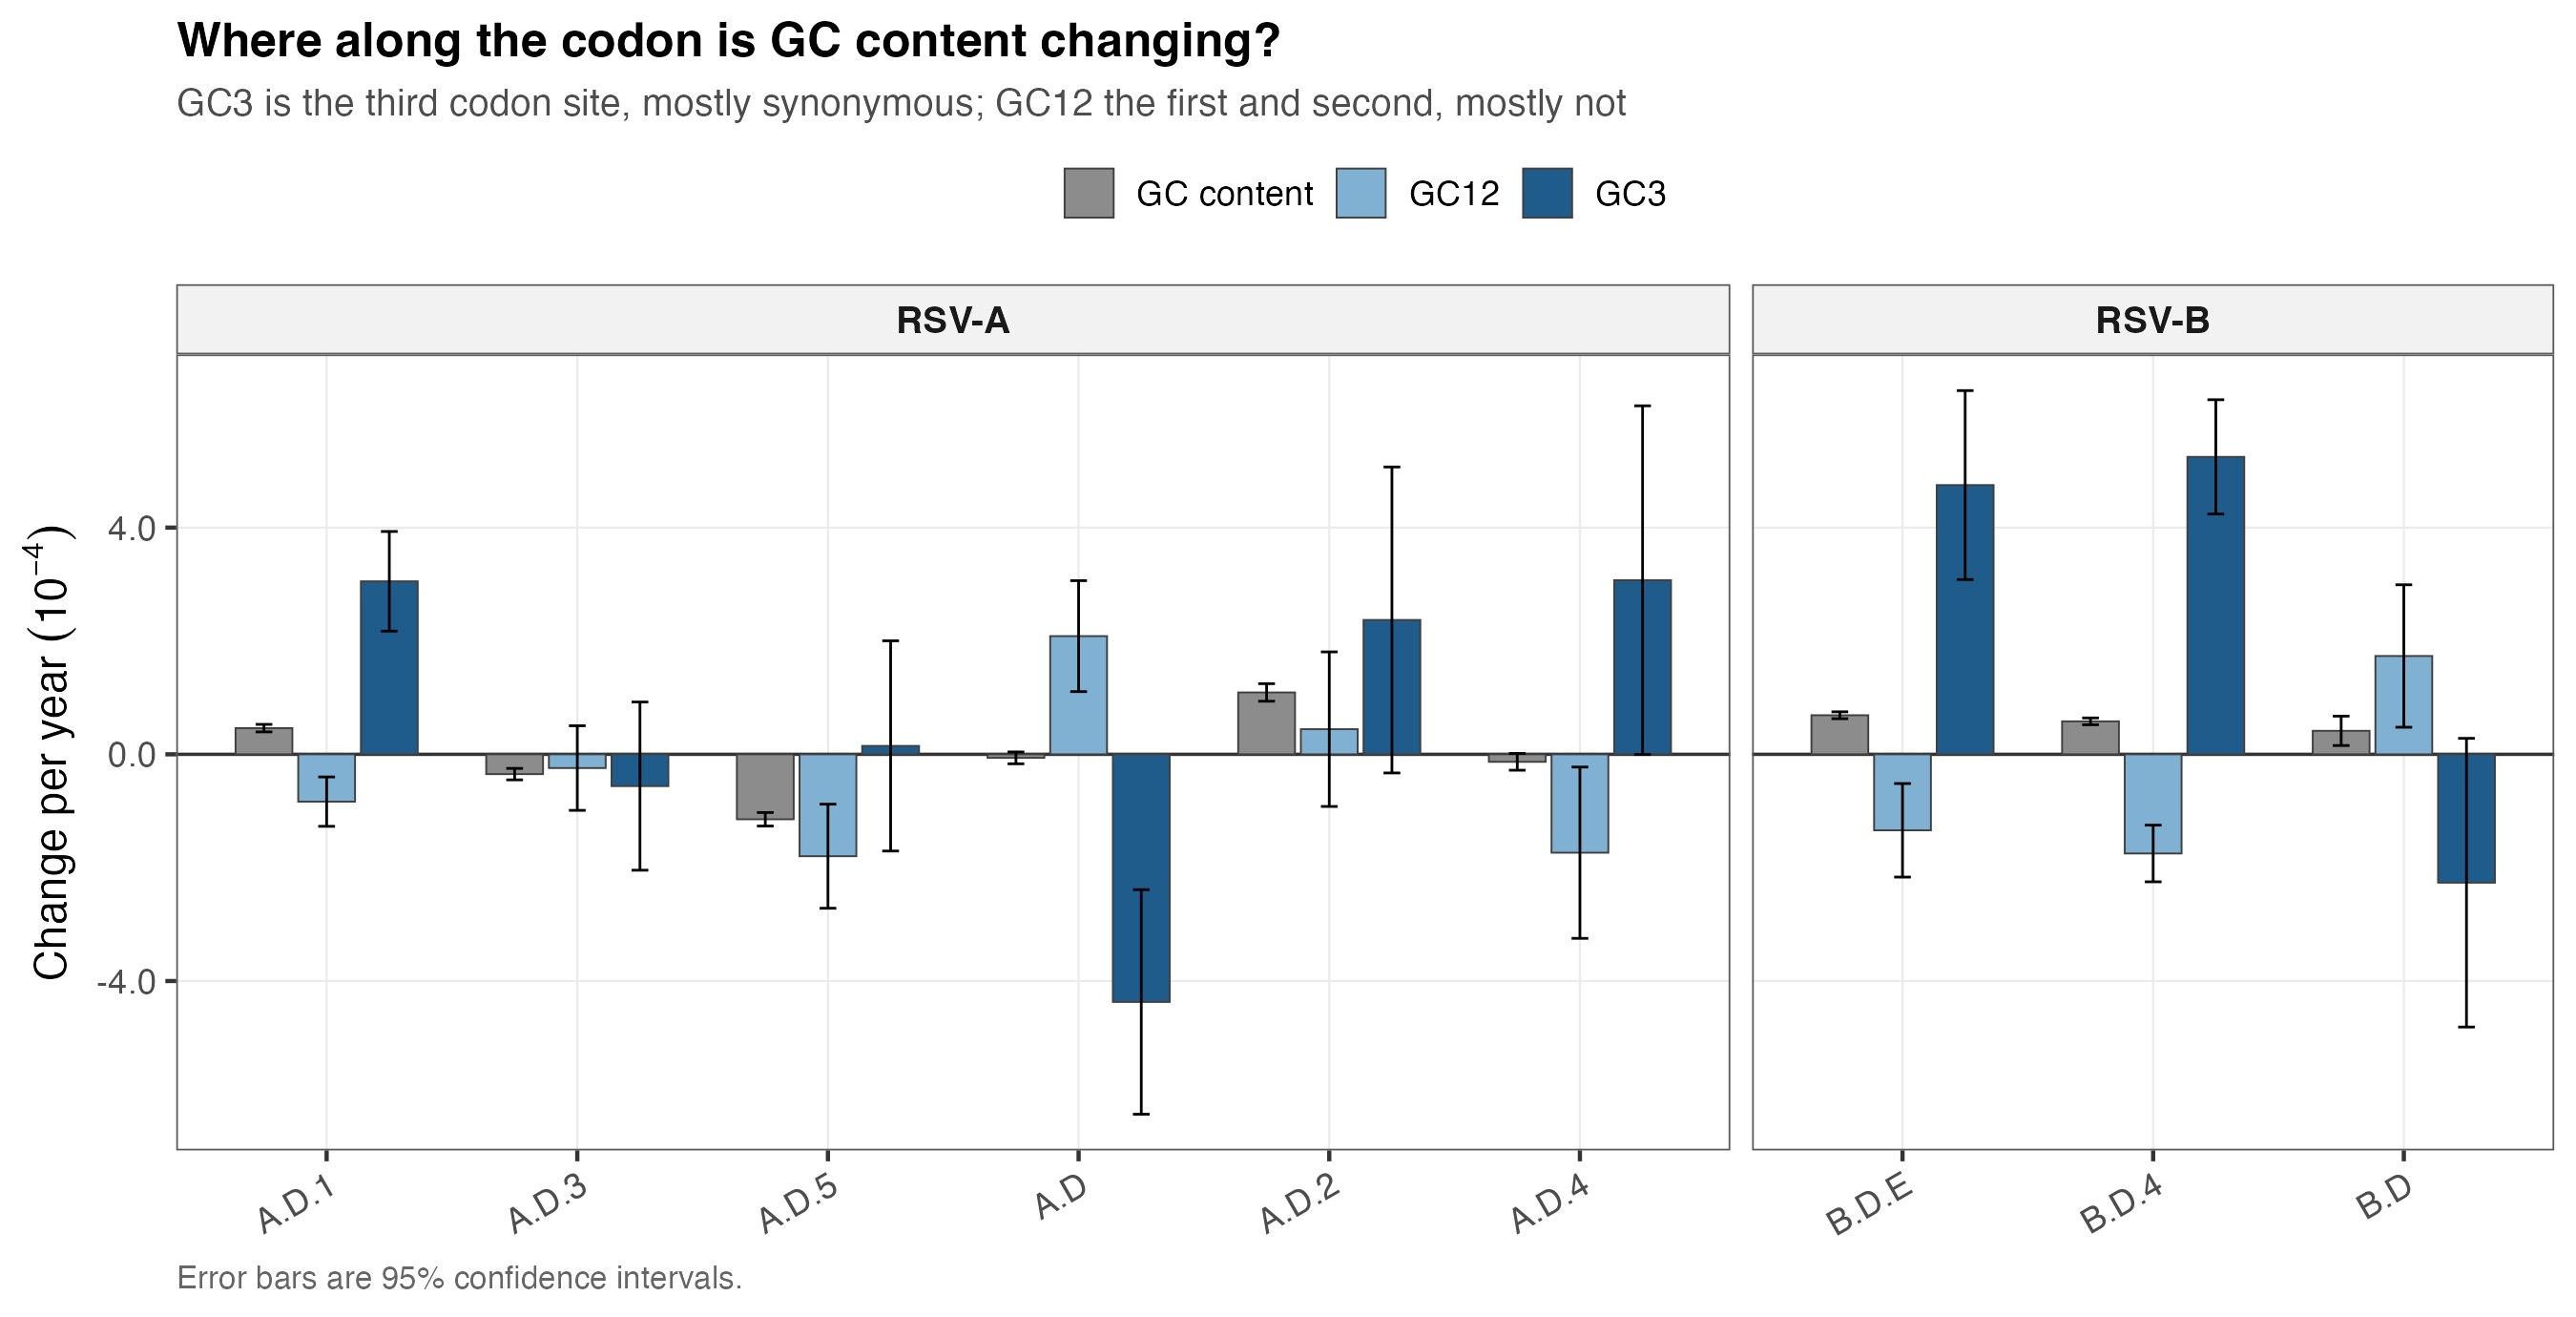

In [7]:
show("fig2_gc3_vs_gc12.png")

### What this shows, and how it differs from the paper

In influenza, GC content fell at **both** site classes, with GC3 falling about 5.65 times faster. That is a coherent picture: composition drifting down, fastest where changes are invisible to the protein.

RSV does not look like that. **GC3 rises in 6 of 8 lineages while GC12 falls in 6 of 8** — the two site classes move in *opposite* directions, so the ratio between them is negative rather than a clean multiple.

Two things follow. The synonymous and non-synonymous sites are clearly under different pressure, which is interesting in itself. But this is not the influenza signature, and it should not be described as reproducing it.

Note the size: the slopes are around 10^-4 per year, so roughly a tenth of a percentage point of GC across the whole decade. Small.

## 3.4  The dinucleotides

The same regression applied to each dinucleotide, reported both as frequency per 1,000 nucleotides (the paper's unit) and as the O/E ratio. The O/E version matters because it already corrects for GC content, so a trend there is not simply GC content moving.

In [8]:
cg = slopes[slopes.feature == "oe_CG"][
    ["Subtype", "lineage_grp", "n", "slope", "ci_lo", "ci_hi", "p", "significant"]]
cg.round(6)

,Subtype,lineage_grp,n,slope,ci_lo,ci_hi,p,significant
8,A,A.D,1020,0.000112,-0.000103,0.000327,0.306744,False
21,A,A.D.1,5090,0.000570,0.000483,0.000656,0.000000,True
34,A,A.D.2,619,0.000157,-0.000030,0.000344,0.099221,False
47,A,A.D.3,4828,-0.000732,-0.000859,-0.000605,0.000000,True
60,A,A.D.4,345,0.000126,-0.000062,0.000315,0.188539,False
73,A,A.D.5,3063,-0.001062,-0.001182,-0.000943,0.000000,True
86,B,B.D.4,4377,0.000369,0.000303,0.000435,0.000000,True
99,B,B.D.E,12484,0.000616,0.000539,0.000693,0.000000,True


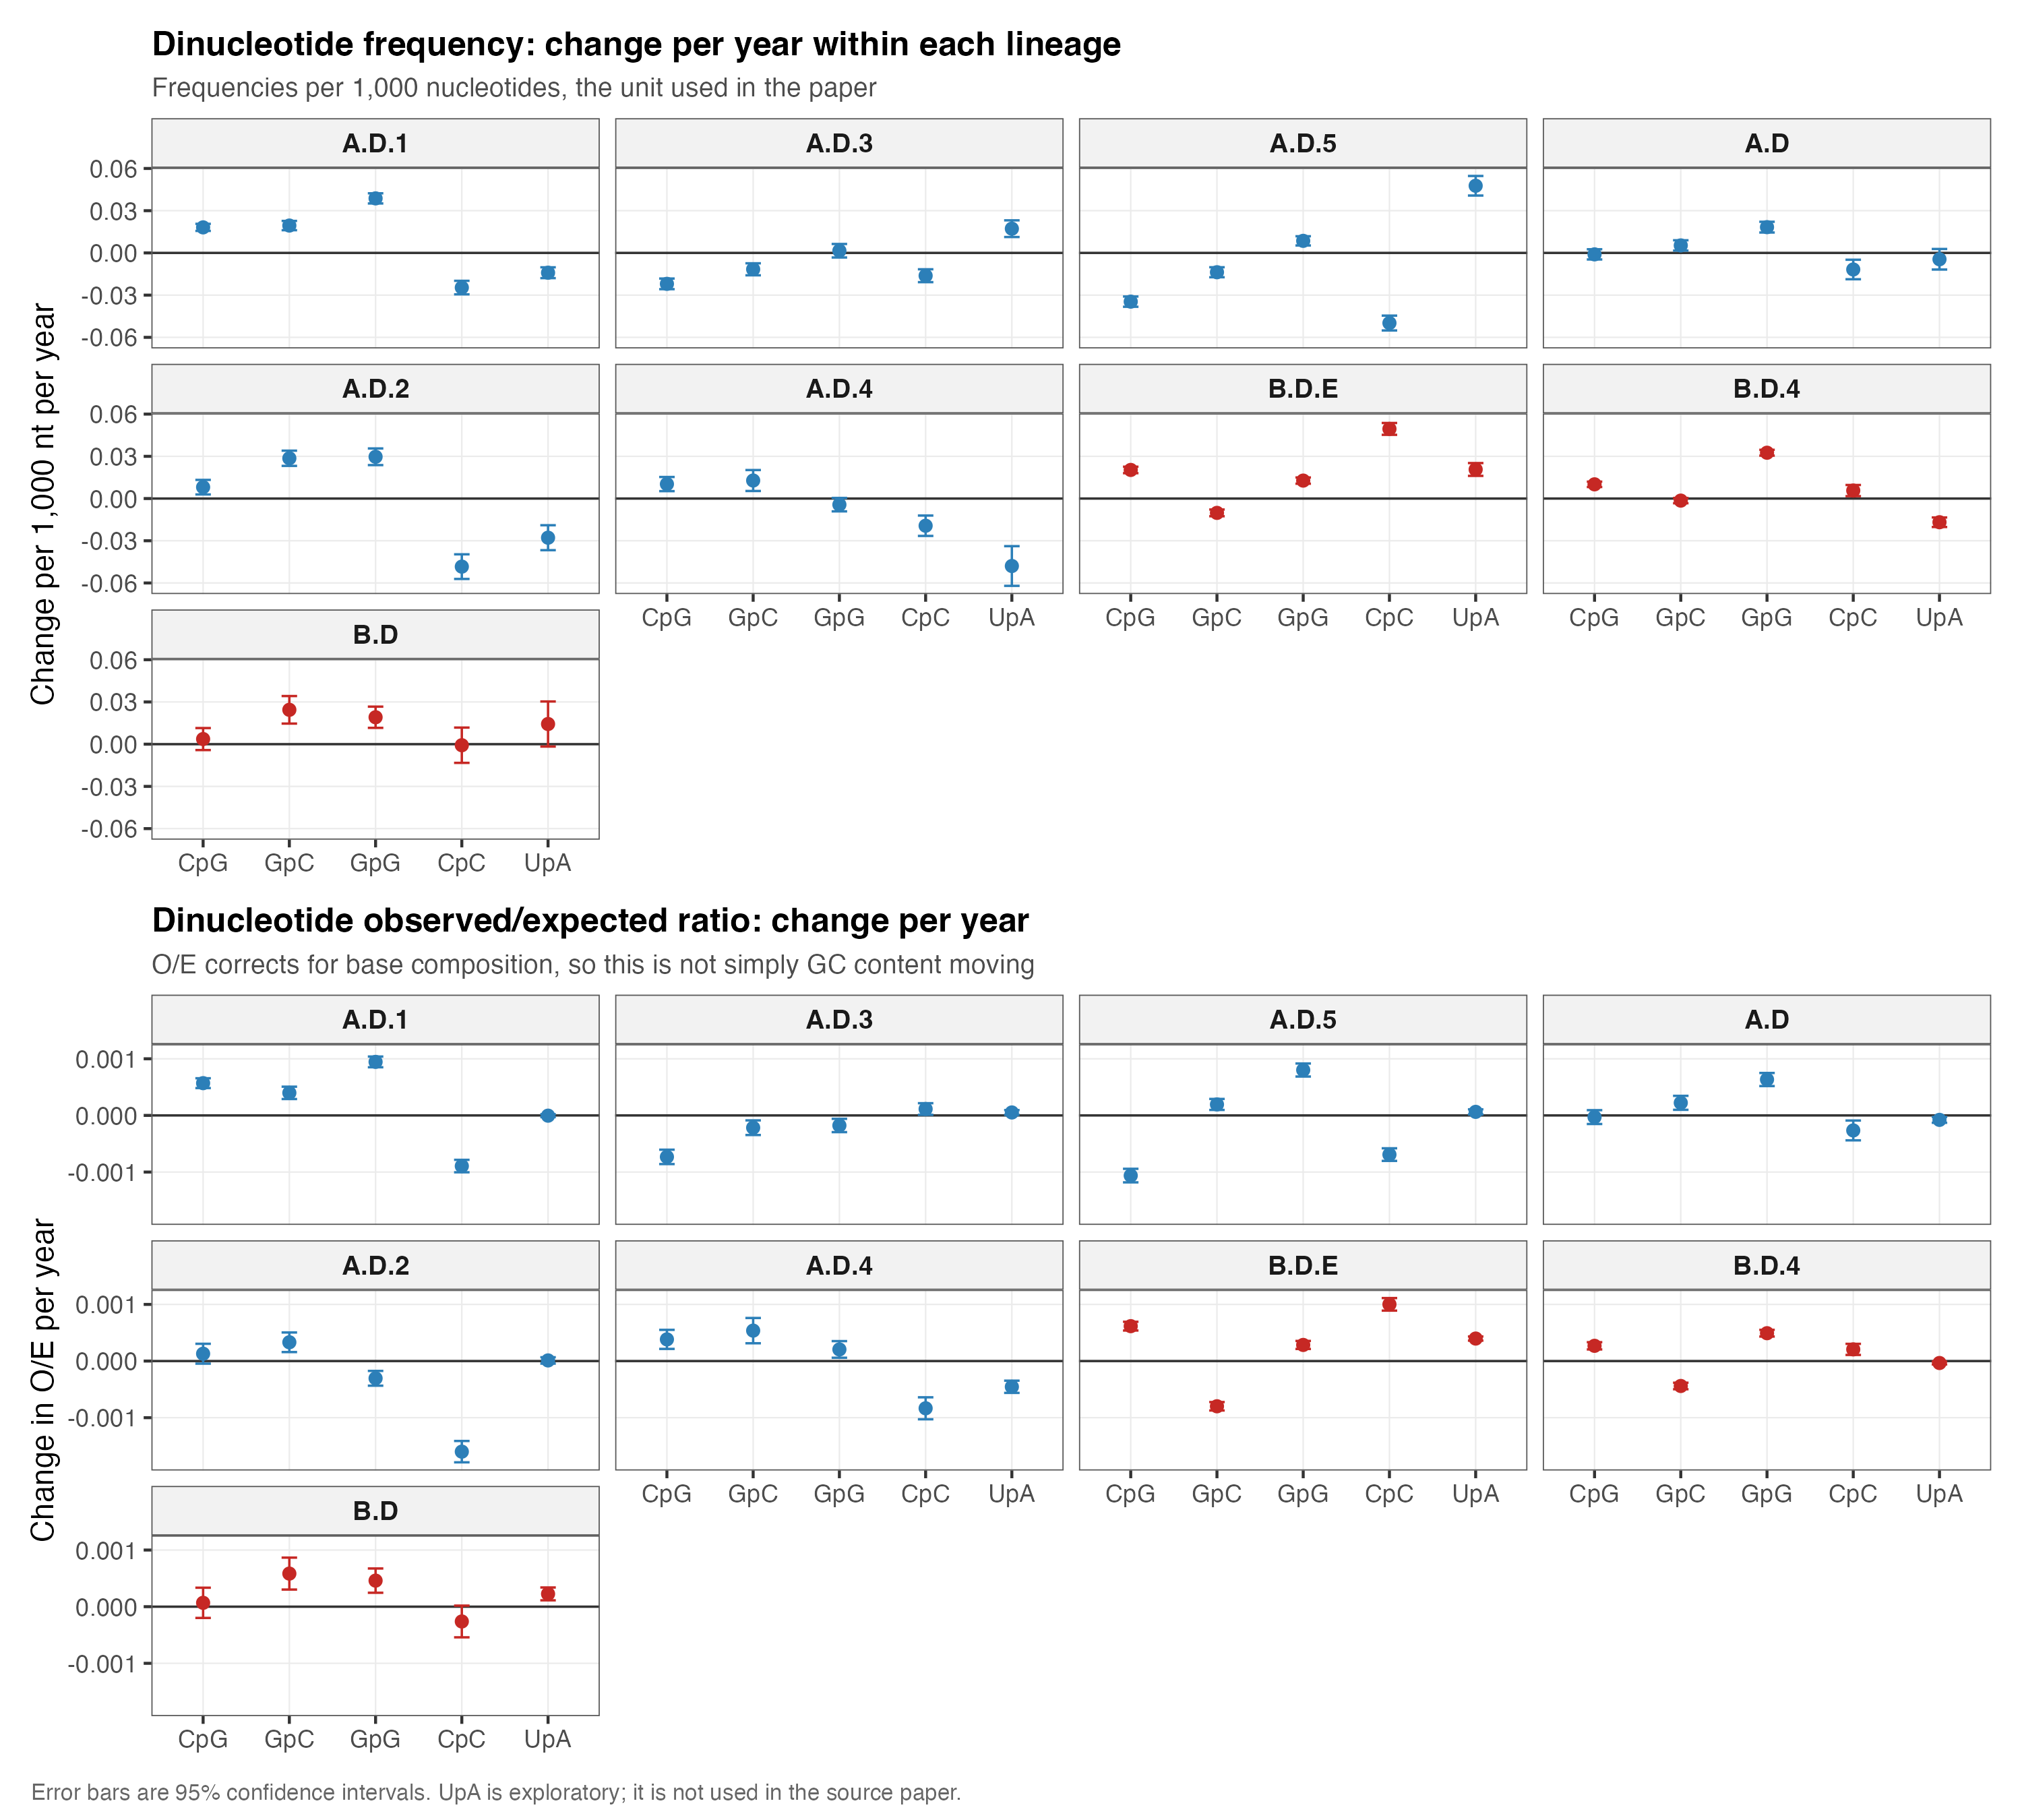

In [9]:
show("fig3_dinucleotide_slopes.png")

### Does geography explain these slopes?

Notebook 01 showed that where RSV was sequenced shifted over the period, including inside single lineages. Repeating the fit with **region held constant** tells us whether a slope is about time or about place.

In [10]:
adj = lineage.lineage_slopes(gdf, ["oe_CG"], covariates=("region",))
cmp = (slopes[slopes.feature == "oe_CG"][["Subtype","lineage_grp","n","slope","p"]]
       .merge(adj[["Subtype","lineage_grp","slope","p"]],
              on=["Subtype","lineage_grp"], suffixes=("", "_adj")))
cmp["same_direction"] = (cmp.slope * cmp.slope_adj) > 0
cmp.round(6)

,Subtype,lineage_grp,n,slope,p,slope_adj,p_adj,same_direction
0,A,A.D,1020,0.000112,0.306744,0.000189,0.138125,True
1,A,A.D.1,5090,0.000570,0.000000,0.000503,0.000000,True
2,A,A.D.2,619,0.000157,0.099221,0.000392,0.000117,True
3,A,A.D.3,4828,-0.000732,0.000000,-0.000743,0.000000,True
4,A,A.D.4,345,0.000126,0.188539,0.000436,0.000106,True
5,A,A.D.5,3063,-0.001062,0.000000,-0.000789,0.000000,True
6,B,B.D.4,4377,0.000369,0.000000,0.000440,0.000000,True
7,B,B.D.E,12484,0.000616,0.000000,0.000231,0.000000,True


Most slopes keep their direction and rough size, so geography is not generating them. The two that move most are the lineages flagged in notebook 01 as having the largest geographic drift, which is what you would hope: the adjustment bites exactly where the problem is.

## 3.5  Is the dinucleotide signal just GC content moving?

The paper's Figure 3b. If a dinucleotide's frequency correlates almost perfectly with GC content, it carries no information beyond GC. Correlations well below 1 mean the dinucleotide is moving on its own.

In [11]:
corr = lineage.gc_vs_dinucleotide_correlation(
    gdf, ["per1k_CG", "per1k_GC", "per1k_GG", "per1k_CC", "per1k_TA"])
corr.groupby("feature").r.agg(["mean", "min", "max"]).round(3)

,mean,min,max
feature,,,
per1k_CC,0.486,0.136,0.717
per1k_CG,0.460,0.256,0.622
per1k_GC,0.479,0.329,0.637
per1k_GG,0.358,0.174,0.515
per1k_TA,-0.644,-0.760,-0.496


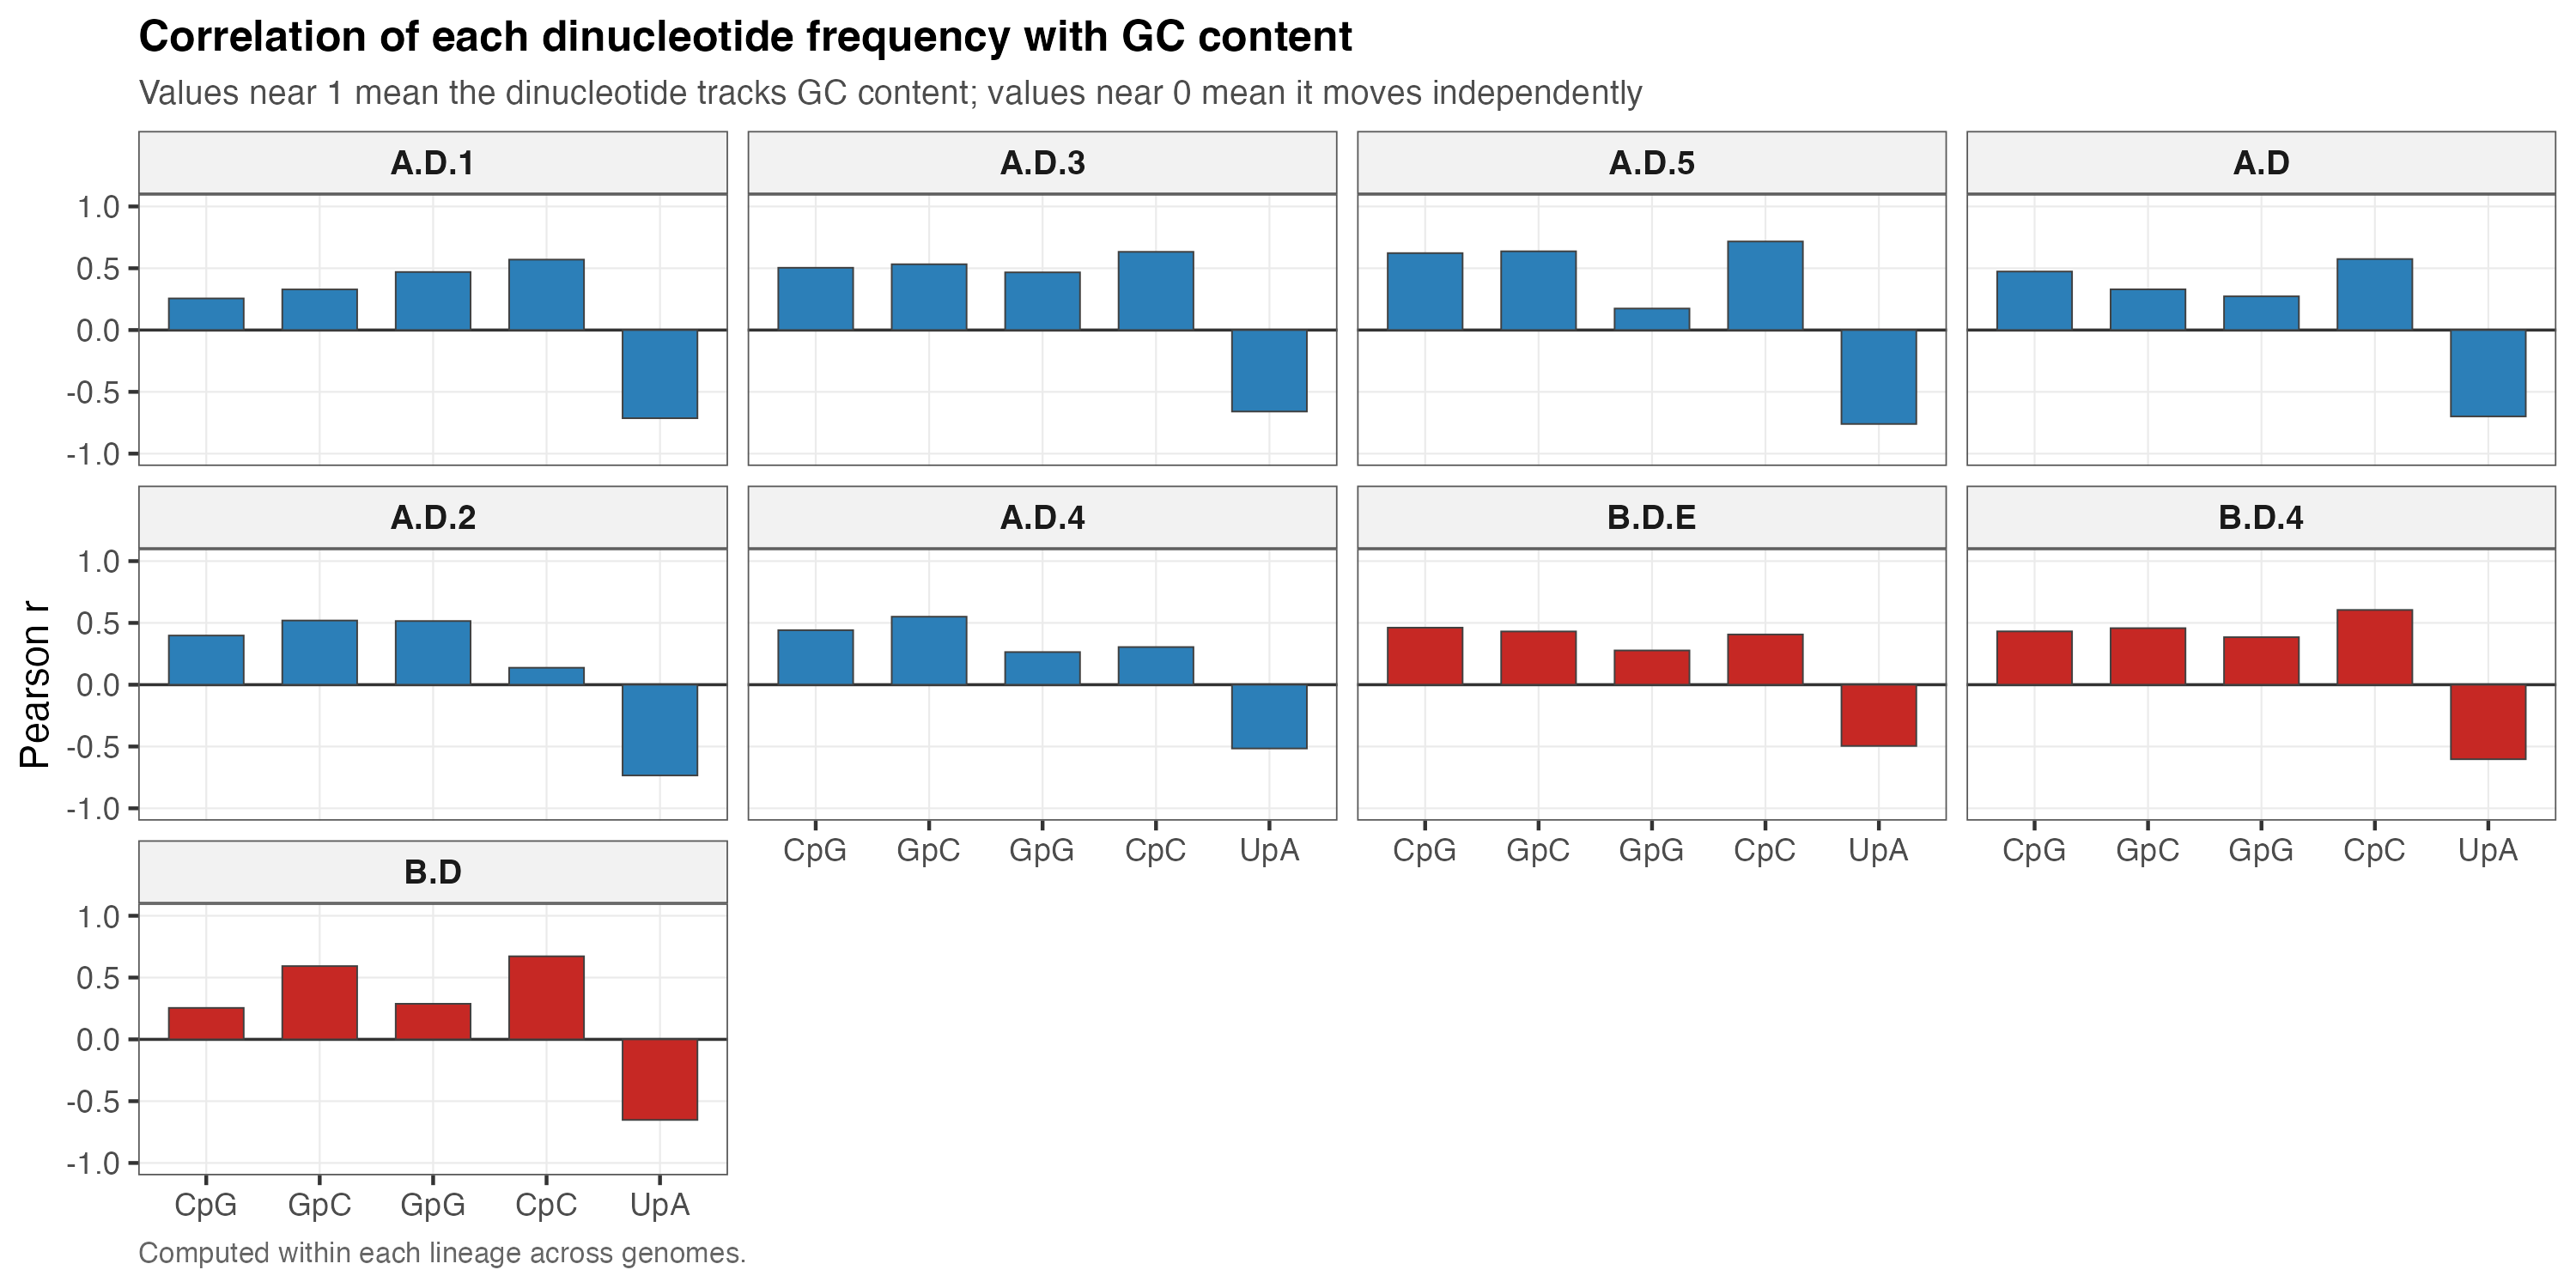

In [12]:
show("fig4_gc_correlation.png")

## 3.6  Sensitivity: does the lineage level drive the result?

Truncating to three levels was a choice. Repeating at level 4 gives more, smaller lineages. If the direction and rough size of the slopes agree, the choice is not driving the conclusion.

In [13]:
gdf4, keep4 = lineage.prepare(genome, level=4)
s4 = lineage.lineage_slopes(gdf4, ["gc_content", "gc3", "oe_CG"])
cmp = pd.concat([slopes[slopes.feature.isin(["gc_content","gc3","oe_CG"])].assign(level=3),
                 s4.assign(level=4)])
cmp.groupby(["level", "feature"]).slope.agg(
    median="median", lineages="size",
    n_negative=lambda s: int((s < 0).sum())).round(6)

median  lineages  n_negative
level feature                                   
3     gc3         0.000268         8           1
      gc_content  0.000017         8           4
      oe_CG       0.000142         8           2
4     gc3         0.000049        19           6
      gc_content  0.000004        19           8
      oe_CG      -0.000351        19          14

**The CpG result does not survive this check.** At three levels the median slope is slightly positive with 3 of 8 lineages negative; at four levels it is negative with 14 of 19 negative. The direction flips depending on how finely lineages are defined, which means the granularity is driving it rather than the biology.

GC3 is steadier: positive at both levels, though weaker at the finer one. GC content overall sits near zero either way.

---

## 3.7  What this notebook found

Stated plainly, because the result is mostly negative.

**1. There is no consistent CpG trend in RSV.** Lineages disagree with each other: A.D.1 and B.D.E rise, A.D.3 and A.D.5 fall. In the influenza paper all twelve persistent lineages moved the same way. Here they do not, and the sensitivity check above shows the overall direction is an artefact of lineage definition.

**2. GC3 and GC12 move in opposite directions**, unlike influenza where both fell. Synonymous and non-synonymous sites are under different pressure in RSV, but the pattern is not the one the paper describes.

**3. Geography is not the explanation.** Slopes keep their direction after region adjustment, so the inconsistency between lineages is real, not a sampling artefact.

**4. All effects are small** — of the order of 10^-4 per year, a fraction of a percentage point across the study period.

### How to read this

RSV has circulated in humans for a very long time and is already well adapted to it. The influenza result came from lineages that had recently entered a *new* host and were still adjusting. There is no equivalent transition inside human RSV, so finding no directional trend is a reasonable outcome rather than a failed analysis.

The clearest signal in this project is not temporal at all. It is the difference between genes, and between the two subtypes, which notebook 04 covers.